# B1: Text Classification using Naive Bayes and Logistic Regression

Preprocess text (tokenization, stop-word removal), convert it to TF-IDF features, train a Naive Bayes classifier and a Logistic Regression model, evaluate them with accuracy, precision, recall, F1-score and the confusion matrix, and compare the two models.

**Dataset:** SMS Spam Collection (5,572 messages) and IMDB Movie Reviews (10,000 sampled from 50,000)

In [2]:
# nltk         : tokenizer, stop words, stemmer
# scikit-learn : TF-IDF, Naive Bayes, Logistic Regression, metrics
# seaborn      : count plot of the labels
!pip install -q nltk scikit-learn pandas seaborn matplotlib

In [3]:
import pandas as pd, seaborn as sns, matplotlib.pyplot as plt
import nltk
for pkg in ["punkt", "punkt_tab", "stopwords"]:
    nltk.download(pkg, quiet=True)
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer

## SMS Spam dataset

In [4]:
df = pd.read_csv("https://raw.githubusercontent.com/justmarkham/pycon-2016-tutorial/master/data/sms.tsv",
                 sep="\t", names=["label", "text"])
df.head()

,label,text
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


label
ham     4825
spam     747
Name: count, dtype: int64


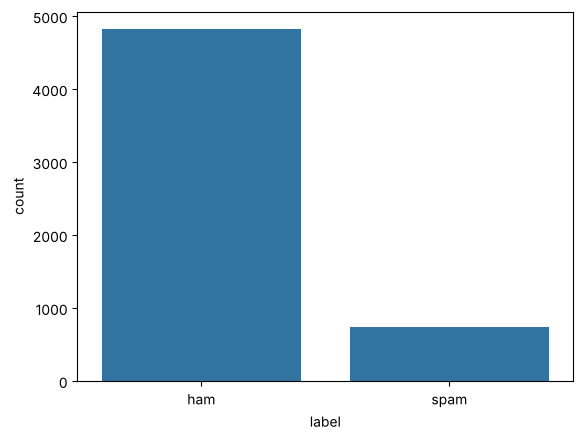

In [5]:
x = df["text"]
y = df["label"]
print(y.value_counts())
sns.countplot(x=y);

## (a) Preprocessing

Tokenize, remove punctuation and numbers, lowercase, remove stop words, stem. First on one sentence.

In [6]:
sent = "Congratulations! You have WON a free ticket. Call 0800 now to claim your prize"
tokens = word_tokenize(sent)
tokens

['Congratulations',
 '!',
 'You',
 'have',
 'WON',
 'a',
 'free',
 'ticket',
 '.',
 'Call',
 '0800',
 'now',
 'to',
 'claim',
 'your',
 'prize']

In [7]:
tokens = [t.lower() for t in tokens if t.isalpha()]      # keep words only, lowercase
tokens

['congratulations',
 'you',
 'have',
 'won',
 'a',
 'free',
 'ticket',
 'call',
 'now',
 'to',
 'claim',
 'your',
 'prize']

In [8]:
swords = stopwords.words("english")
tokens = [t for t in tokens if t not in swords]
tokens

['congratulations', 'free', 'ticket', 'call', 'claim', 'prize']

In [9]:
ps = PorterStemmer()
tokens = [ps.stem(t) for t in tokens]
tokens

['congratul', 'free', 'ticket', 'call', 'claim', 'prize']

In [10]:
def clean_text(sent):
    tokens = word_tokenize(sent)
    tokens = [t.lower() for t in tokens if t.isalpha()]
    tokens = [t for t in tokens if t not in swords]
    return [ps.stem(t) for t in tokens]

clean_text(sent)

['congratul', 'free', 'ticket', 'call', 'claim', 'prize']

## (b) TF-IDF features

Split first, then fit TF-IDF on the training texts only, so the test messages stay unseen. `stratify=y` keeps the same spam share in both parts.

In [11]:
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.25, random_state=0, stratify=y)

tfidf = TfidfVectorizer(analyzer=clean_text)
x_train_vec = tfidf.fit_transform(x_train)       # learn the vocabulary from training texts
x_test_vec = tfidf.transform(x_test)             # reuse it for the test texts
x_train_vec.shape, x_test_vec.shape

((4179, 5088), (1393, 5088))

## (c) Naive Bayes and Logistic Regression

In [12]:
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression

nb_model = MultinomialNB()
nb_model.fit(x_train_vec, y_train)

lr_model = LogisticRegression()
lr_model.fit(x_train_vec, y_train)

y_pred_nb = nb_model.predict(x_test_vec)
y_pred_lr = lr_model.predict(x_test_vec)

## (d) Evaluation

In [13]:
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

print("NAIVE BAYES")
print(classification_report(y_test, y_pred_nb))
print("LOGISTIC REGRESSION")
print(classification_report(y_test, y_pred_lr))

NAIVE BAYES
              precision    recall  f1-score   support

         ham       0.96      1.00      0.98      1206
        spam       1.00      0.73      0.85       187

    accuracy                           0.96      1393
   macro avg       0.98      0.87      0.91      1393
weighted avg       0.97      0.96      0.96      1393

LOGISTIC REGRESSION
              precision    recall  f1-score   support

         ham       0.95      1.00      0.98      1206
        spam       0.98      0.70      0.82       187

    accuracy                           0.96      1393
   macro avg       0.97      0.85      0.90      1393
weighted avg       0.96      0.96      0.95      1393



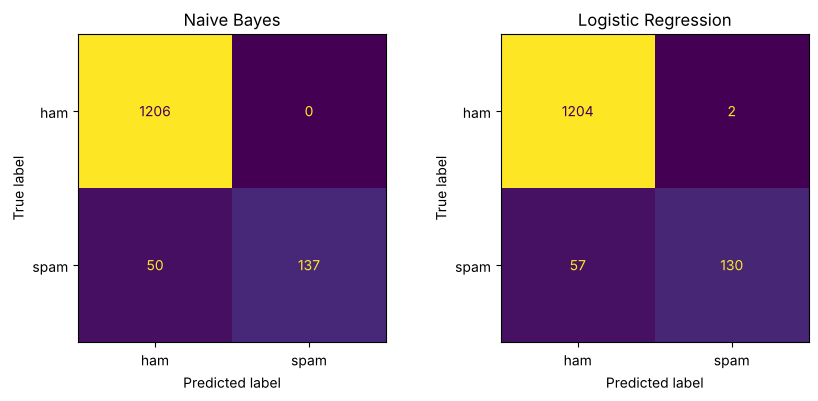

In [14]:
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_nb, ax=ax[0], colorbar=False)
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_lr, ax=ax[1], colorbar=False)
ax[0].set_title("Naive Bayes"); ax[1].set_title("Logistic Regression"); plt.show()

## (e) Compare the two models

In [15]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

def scores(y_true, y_pred, pos):
    return {"accuracy": accuracy_score(y_true, y_pred),
            "precision": precision_score(y_true, y_pred, pos_label=pos),
            "recall": recall_score(y_true, y_pred, pos_label=pos),
            "f1": f1_score(y_true, y_pred, pos_label=pos)}

sms_results = pd.DataFrame({"Naive Bayes": scores(y_test, y_pred_nb, "spam"),
                            "Logistic Regression": scores(y_test, y_pred_lr, "spam")}).T.round(3)
sms_results

,accuracy,precision,recall,f1
Naive Bayes,0.964,1.000,0.733,0.846
Logistic Regression,0.958,0.985,0.695,0.815


In [16]:
# spam messages the models missed
missed = x_test[(y_test == "spam") & (y_pred_nb == "ham")]
print(len(missed), "spam messages predicted as ham by Naive Bayes, for example:")
clean_examples = missed[~missed.str.contains("sex|xxx|fancy|babe|hot|naughty|horny|dating|date", case=False)]   # skip adult spam for class
for m in clean_examples.head(3):
    print("-", m)

50 spam messages predicted as ham by Naive Bayes, for example:
- FREE GAME. Get Rayman Golf 4 FREE from the O2 Games Arcade. 1st get UR games settings. Reply POST, then save & activ8. Press 0 key for Arcade. Termsapply
- Email AlertFrom: Jeri StewartSize: 2KBSubject: Low-cost prescripiton drvgsTo listen to email call 123
- <Forwarded from 448712404000>Please CALL 08712404000 immediately as there is an urgent message waiting for you.


## IMDB Movie Reviews: same steps

In [17]:
imdb = pd.read_csv("https://raw.githubusercontent.com/Ankit152/IMDB-sentiment-analysis/master/IMDB-Dataset.csv")
imdb = imdb.sample(10000, random_state=0)
imdb["review"] = imdb["review"].str.replace("<br />", " ")
print(imdb["sentiment"].value_counts())
imdb.head(3)

sentiment
negative    5035
positive    4965
Name: count, dtype: int64


,review,sentiment
11841,John Cassavetes is on the run from the law. He...,positive
19602,It's not just that the movie is lame. It's mor...,negative
45519,"Well, if it weren't for Ethel Waters and a 7-y...",negative


In [18]:
x_train, x_test, y_train, y_test = train_test_split(imdb["review"], imdb["sentiment"], test_size=0.25,
                                                    random_state=0, stratify=imdb["sentiment"])
tfidf = TfidfVectorizer(analyzer=clean_text)
x_train_vec = tfidf.fit_transform(x_train)
x_test_vec = tfidf.transform(x_test)
x_train_vec.shape

(7500, 30472)

In [19]:
y_pred_nb = MultinomialNB().fit(x_train_vec, y_train).predict(x_test_vec)
y_pred_lr = LogisticRegression(max_iter=1000).fit(x_train_vec, y_train).predict(x_test_vec)

print("NAIVE BAYES"); print(classification_report(y_test, y_pred_nb))
print("LOGISTIC REGRESSION"); print(classification_report(y_test, y_pred_lr))

NAIVE BAYES
              precision    recall  f1-score   support

    negative       0.82      0.89      0.85      1259
    positive       0.88      0.80      0.83      1241

    accuracy                           0.84      2500
   macro avg       0.85      0.84      0.84      2500
weighted avg       0.85      0.84      0.84      2500

LOGISTIC REGRESSION
              precision    recall  f1-score   support

    negative       0.88      0.85      0.87      1259
    positive       0.85      0.89      0.87      1241

    accuracy                           0.87      2500
   macro avg       0.87      0.87      0.87      2500
weighted avg       0.87      0.87      0.87      2500



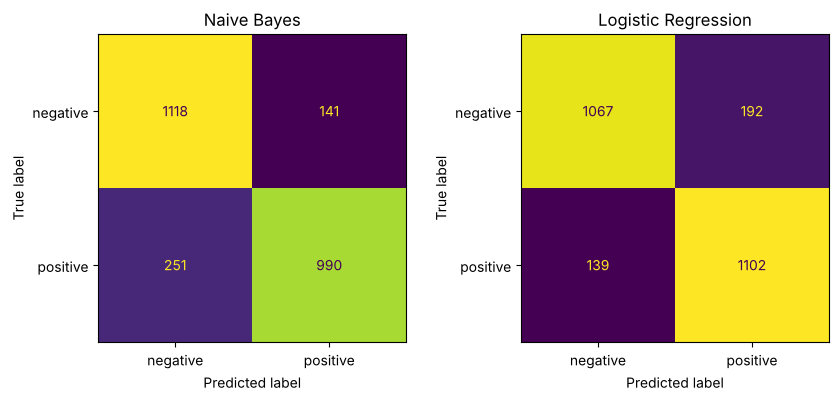

In [20]:
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_nb, ax=ax[0], colorbar=False)
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_lr, ax=ax[1], colorbar=False)
ax[0].set_title("Naive Bayes"); ax[1].set_title("Logistic Regression"); plt.show()

In [21]:
imdb_results = pd.DataFrame({"Naive Bayes": scores(y_test, y_pred_nb, "positive"),
                             "Logistic Regression": scores(y_test, y_pred_lr, "positive")}).T.round(3)
pd.concat({"SMS (spam = positive class)": sms_results, "IMDB": imdb_results})

accuracy  precision  recall  \
SMS (spam = positive class) Naive Bayes             0.964      1.000   0.733   
                            Logistic Regression     0.958      0.985   0.695   
IMDB                        Naive Bayes             0.843      0.875   0.798   
                            Logistic Regression     0.868      0.852   0.888   

                                                    f1  
SMS (spam = positive class) Naive Bayes          0.846  
                            Logistic Regression  0.815  
IMDB                        Naive Bayes          0.835  
                            Logistic Regression  0.869

## Justification of the results
- **SMS:** both models reach about 96% accuracy, but accuracy hides the imbalance (only about 13% spam). Both have very high spam precision (almost no ham marked as spam) but miss a quarter or more of the spam (recall about 0.7). Naive Bayes is slightly better here. For a spam filter, look at spam recall and precision, not accuracy. `class_weight="balanced"` in Logistic Regression is one way to raise spam recall.
- **IMDB:** balanced classes, so accuracy is meaningful. Logistic Regression learns a weight for each word and handles words that appear together better than Naive Bayes, which assumes words are independent; it usually scores a little higher.
- Naive Bayes trains faster and works well with little data; Logistic Regression is usually more accurate when there is enough data.
- Removing stop words also removes "not", which hurts sentiment ("not good"); keeping negations is a simple improvement.